[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AIforPhilanthropy/eduall/blob/main/protocols/agentic_mimicking_protocols/TraditionalML/5_Survival/Survival_Protocol.ipynb)

# EduAll Foundation — Grant Call 2026
## Group Project Report: Traditional Machine Learning — Survival Analysis of the Financial Runway

**Protocol:** `protocols/humaAI_Machine_Learning.pdf` — Human-AI condition, Approach 1 of 3 (traditional ML).
**Modeling path chosen:** example 5 of the protocol, *Financial-runway hazard (Cox proportional hazards)*.
**Group:** Group ML-5, four students (A, B, C, D).
**Input data:** `data/EduAll_500_Applications_Dataset.csv` and the 500 application files in
`data/individual_applications/`.

We ask a different question from the other approaches: *who will run out of money before finishing the degree, and how soon?* We construct each applicant's financial runway, treat running out before completion as the event, fit a Cox proportional-hazards model, and use the predicted hazard as an urgency score.

This notebook **is** our project report. It follows the protocol's four steps:

1. **Anchor the model's objective** — from the mission statement and the grant call: the 7 eligibility
   (hard, pass/fail) and 5 priority (soft, scored) criteria, plus the nuances we add as a group.
2. **Choose and execute a modeling path** — and why we chose it.
3. **Build and validate** — features used and excluded, fitting, the validation criterion, seed-sensitivity
   runs, and a human review of the model's output against the underlying records.
4. **Documentation and reproducibility** — full specification, which decisions are the model's and which
   are ours, the final funding list, and the output files `decision_progression.csv` and
   `final_allocation.csv`.

In [ ]:
# --- Get the data -------------------------------------------------------------------------------
# On Google Colab this cell downloads the course repository (data + notebooks) from GitHub and moves into this
# notebook's folder, so every data path below works as on the course computers. Locally it does nothing.
import os, pathlib, subprocess
REPO_URL = "https://github.com/AIforPhilanthropy/eduall.git"
NOTEBOOK_DIR = "protocols/agentic_mimicking_protocols/TraditionalML/5_Survival"          # this notebook's folder inside the repository
here = pathlib.Path.cwd()
if not any((p / "data" / "EduAll_500_Applications_Dataset.csv").exists() for p in [here, *here.parents]):
    if not pathlib.Path("/content/eduall").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/eduall"], check=True)
    os.chdir(pathlib.Path("/content/eduall") / NOTEBOOK_DIR)
print("working directory:", os.getcwd())

---
## Step 1 — Anchor the model's objective

*Budget: ~13.0h for a 4-student group.*

We read the foundation's **Organization Profile** (mission and values) and the **Grant Call 2026**
(eligibility, ineligible categories, priority considerations, weighted evaluation criteria, award rules),
and the FAQ where the call refers to it.

**Mission (Organization Profile):** *"Our focus is not on academic excellence or competition, but rather on
identifying students with genuine financial need and providing them with the means to pursue their
studies."*

### 1.1 Eligibility criteria (hard, pass/fail, n = 7)

These are the call's seven *Primary Eligibility Requirements*. The last column says how we check each one in
the data, including our group's decisions where the call leaves room for interpretation.

| # | Criterion (Grant Call) | How we check it | Our decision |
|---|---|---|---|
| H1 | Non-Swiss citizen | `country_origin` | All 500 applicants are international by construction: pass. |
| H2 | Legally residing in Switzerland (valid permit B, C, F, S...; pending permits case by case) | `residency_permit`, plus the ineligible category *"Permit C and significant family financial resources"* | Permits B, C, F, S pass; Pending permits are eligible and *conditional*. Permit C with a supporting household of CHF 5,500/month or more fails ("significant family resources"). |
| H3 | Accepted or enrolled at an accredited Swiss institution | `university` | All listed institutions are accredited: pass. |
| H4 | Documented genuine financial need | expected 2027/28 shortfall `monthly_expenses − family support − expected personal income`, for the months of study inside the grant period (Sep 2027 – Aug 2028) | Pass if the expected 2027/28 shortfall is positive in the grant period (months from the completion date in the file). |
| H5 | Satisfactory academic standing, normally GPA ≥ 2.5 (exceptions if the reasons are explained) | `gpa`, `academic_standing` | GPA ≥ 2.5 passes. Below 2.5: eligible, award *conditional* on the explanation the call requires. |
| H6 | Bachelor's, master's or doctoral degree, full-time or part-time | `study_level`, `study_mode` | All applicants qualify: pass. |
| H7 | No outstanding legal or immigration issues | not observable in the data | Assumed satisfied; pending permits are handled in H2. |


### 1.2 Priority criteria (soft, scored, n = 5)

| # | Criterion (Grant Call weight) | What it means for us | Variables |
|---|---|---|---|
| S1 | Financial need (40%) | Whether, and how soon, the applicant's resources run out before graduation. This is the core of our model. | runway (savings, monthly gap, other scholarships), time to completion |
| S2 | Academic motivation & potential (25%) | Used only as a check: a student close to completion who would drop out is a large loss. | `progress`, `gpa` |
| S3 | Personal resilience & determination (20%) | Not in the hazard model. Considered in the final priority (Step 4). | `resil_count`, `risk_count` |
| S4 | Contribution to diversity (10%) | Low-income country, first generation: covariates of the hazard model, and part of the final priority. | `gni_tier`, `risk_first_generation` |
| S5 | Alignment with EduAll values (5%) | Final priority only. | `resilience_community_engagement`, `resilience_volunteer_experience` |

The call also names **priority groups**: students from low-income countries (GNI per capita below USD 3,000,
`gni_tier == 1`), first-generation students, students from under-represented regions, and students
demonstrating exceptional resilience.


### 1.3 Nuances we add as a group

* **Need is a matter of time.** Two applicants with the same monthly gap are in very different positions if one
  has savings that last until graduation and the other has none. The FAQ says the committee considers *how long you
  still need to complete your degree* and *your savings*. A survival model combines exactly these two durations.
* **Savings already cover the year before the grant.** The grant starts in September 2027. Savings first have to
  cover the gap from September 2026 to August 2027. Only what remains after that is deducted from the grant-period
  request.
* **Award size.** 75% of the request, minimum CHF 1,000.

❓ **Question for students:** our urgency model rewards applicants who have *no* savings. Could this penalise
applicants who saved carefully for their studies? Is that consistent with the call's values?

---
## Step 2 — Choose and execute a modeling path

*Budget: ~27.6h.*

We chose the protocol's **survival-analysis path**:

* **Runway** (months) = savings ÷ net monthly gap, where net monthly gap = expected 2027/28 shortfall − other
  scholarships / 12. With a gap of zero or less, the runway is unlimited;
* **Time to completion** (months from September 2026) = from the expected completion date stated in the application
  file (we cross-check it against `semesters_in_program` below);
* **Duration** $T = \min(\text{runway}, \text{time to completion})$; **event** = runway < time to completion
  (the money runs out before graduation). Applicants whose runway reaches graduation are **right-censored** at
  their completion time: we observe that they *do not* run out within their programme;
* **Model:** Cox proportional hazards (`lifelines`), with covariates describing the applicant's financial structure
  and situation, *excluding savings and the gap itself*. Those define the duration, so including them would make
  the model trivially circular. The model's partial hazard is our urgency score.

In [1]:
import importlib.util, subprocess, sys
_missing = [p for p, m in [("lifelines", "lifelines")] if importlib.util.find_spec(m) is None]
if _missing:                                   # e.g. on Google Colab
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_missing], check=True)
import pathlib, re, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
warnings.filterwarnings("ignore")
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import k_fold_cross_validation, concordance_index
from lifelines.statistics import proportional_hazard_test
from scipy.stats import spearmanr
SEED = 2026
mpl.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 9})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

In [2]:
# Data: works from the course folder (protocols/agentic_mimicking_protocols/TraditionalML/<approach>/)
# and on Google Colab (upload the CSV and individual_applications.zip when asked).
CANDIDATES = [pathlib.Path("../../../../data"), pathlib.Path("../../../data"), pathlib.Path("data"), pathlib.Path(".")]
DATA = next((b for b in CANDIDATES if (b / "EduAll_500_Applications_Dataset.csv").exists()), None)
if DATA is None:
    from google.colab import files            # only reached on Colab
    print("Upload EduAll_500_Applications_Dataset.csv and individual_applications.zip")
    files.upload()
    DATA = pathlib.Path(".")
APPS = DATA / "individual_applications"
if not APPS.exists() and (DATA / "individual_applications.zip").exists():
    with zipfile.ZipFile(DATA / "individual_applications.zip") as z:
        z.extractall(DATA)

df = pd.read_csv(DATA / "EduAll_500_Applications_Dataset.csv", keep_default_na=False).set_index("student_id", drop=False)
df.index.name = None
docs = {sid: (APPS / f"{sid}_application.md").read_text(encoding="utf-8") for sid in df.student_id}
print(df.shape, "| application files:", len(docs))

(500, 44) | application files: 500


In [3]:
# Quantities every approach needs, computed from the call's own rules
RISK = ["risk_first_generation", "risk_refugee_asylum", "risk_disability", "risk_housing_insecurity",
        "risk_family_emergency", "risk_language_barrier", "risk_parent_student", "risk_undocumented_status"]
RESIL = ["resilience_volunteer_experience", "resilience_work_experience", "resilience_leadership_role",
         "resilience_community_engagement", "resilience_overcame_adversity"]
CAP = {"Bachelor's": 8000, "Master's": 6500, "Doctoral": 5000}          # annual maximum by level
REQUIRED = {"Bachelor's": 40, "Master's": 12, "Doctoral": 12}             # courses per degree

# Expected completion is stated in each application form; we read it from the file.
MONTH = {"January": 1, "July": 7}
def completion(text):
    m = re.search(r"\*\*Expected Completion:\*\*\s*(January|July) (\d{4})", text)
    return (int(m.group(2)), MONTH[m.group(1)]) if m else (None, None)

df["completion_year"], df["completion_month"] = zip(*[completion(docs[s]) for s in df.student_id])
# months of study inside the grant period Sep 2027 - Aug 2028 (finish Jan 2028 -> 5, Jul 2028 -> 11, later -> 12)
grant_end = (2028, 8)
def months_in_grant(y, m):
    if y is None: return 12
    if (y, m) < (2027, 9): return 0
    if (y, m) >= grant_end: return 12
    return (y - 2027) * 12 + m - 9 + 1
df["months_in_grant"] = [months_in_grant(y, m) for y, m in zip(df.completion_year, df.completion_month)]
df["months_to_completion"] = [(y - 2026) * 12 + m - 9 + 1 for y, m in zip(df.completion_year, df.completion_month)]  # from Sep 2026

df["need_2027"] = (df.monthly_expenses_chf - df.family_income_chf - df.expected_personal_income_2027_chf).clip(lower=0)
df["shortfall_ratio"] = (df.need_2027 / df.monthly_expenses_chf).clip(0, 1)
df["risk_count"] = df[RISK].sum(axis=1)
df["resil_count"] = df[RESIL].sum(axis=1)
df["progress"] = (df.courses_completed / df.study_level.map(REQUIRED)).clip(0, 1)
df["cap_period"] = df.study_level.map(CAP) * df.months_in_grant / 12
print(df.months_in_grant.value_counts().sort_index().to_dict())

{5: 50, 11: 283, 12: 167}


In [4]:

PERMIT_C_LIMIT = 5500      # "significant family financial resources" for Permit C (our threshold)
df["H1"] = np.where(df.country_origin != "Switzerland", "pass", "fail")
df["H2"] = np.select([(df.residency_permit == "C") & (df.family_household_income_chf >= PERMIT_C_LIMIT),
                      df.residency_permit == "Pending"],
                     ["fail (Permit C, household >= CHF 5,500)", "conditional (permit pending)"], "pass")
df["H3"] = np.where(df.university.str.len() > 0, "pass", "fail")
df["H4"] = np.where((df.need_2027 > 0) & (df.months_in_grant > 0), "pass", "fail (no shortfall in grant period)")
df["H5"] = np.where(df.gpa >= 2.5, "pass", "conditional")   # explanation required at interview
df["H6"] = np.where(df.study_level.isin(CAP) & df.study_mode.isin(["Full-time", "Part-time"]), "pass", "fail")
df["H7"] = "pass (assumed)"
HARD = ["H1", "H2", "H3", "H4", "H5", "H6", "H7"]
df["eligible"] = ~df[HARD].apply(lambda c: c.str.startswith("fail")).any(axis=1)
df["conditional"] = df[HARD].apply(lambda c: c.str.startswith("conditional")).any(axis=1)
summary = pd.DataFrame({h: df[h].value_counts() for h in HARD}).fillna(0).astype(int)
display(summary)
print(f"eligible: {df.eligible.sum()} of {len(df)} (of which conditional: {(df.eligible & df.conditional).sum()})")

,H1,H2,H3,H4,H5,H6,H7
conditional,0,0,0,0,81,0,0
conditional (permit pending),0,16,0,0,0,0,0
"fail (Permit C, household >= CHF 5,500)",0,23,0,0,0,0,0
fail (no shortfall in grant period),0,0,0,76,0,0,0
pass,500,461,500,424,419,500,0
pass (assumed),0,0,0,0,0,0,500


eligible: 412 of 500 (of which conditional: 74)


In [5]:
# Net monthly gap (2027/28 terms) and savings left after bridging Sep 2026 - Aug 2027
df["net_gap"] = (df.need_2027 - df.external_scholarship_amount_chf / 12).clip(lower=0)
df["savings_after_bridge"] = (df.savings_chf - 12 * df.net_gap).clip(lower=0)

In [6]:
# Award request for the grant period: shortfall x months, minus other scholarships and savings, capped
# Savings: savings that remain after covering the net gap from Sep 2026 to Aug 2027 are deducted
df["scholarship_period"] = df.external_scholarship_amount_chf * df.months_in_grant / 12
df["savings_counted"] = df.savings_after_bridge.round()
df["request"] = (df.need_2027 * df.months_in_grant - df.scholarship_period - df.savings_counted).clip(lower=0)
df["request"] = np.minimum(df.request, df.cap_period).round()
print(f"eligible applicants with a positive request: {(df.eligible & (df.request > 0)).sum()}; "
      f"their total request: CHF {df.loc[df.eligible, 'request'].sum():,.0f} vs budget CHF 500,000")

eligible applicants with a positive request: 386; their total request: CHF 2,173,172 vs budget CHF 500,000


---
## Step 3 — Build and validate

*Budget: ~81.2h.*

### 3.1 Durations, events and censoring

In [7]:
df["time_to_completion"] = df.months_to_completion.astype(float)
df["runway"] = np.where(df.net_gap > 0, df.savings_chf / df.net_gap.where(df.net_gap > 0), np.inf)
df["event"] = (df.runway < df.time_to_completion).astype(int)
df["T"] = np.minimum(df.runway, df.time_to_completion).clip(lower=0.5)    # no savings -> runs out in the first month
E = df[df.eligible].copy()
print(f"eligible: {len(E)} | event (runs out before completion): {E.event.sum()} | right-censored: {(1 - E.event).sum()}")
print("eligible with zero savings (runway 0):", (E.savings_chf == 0).sum())
print("time to completion (months):", E.time_to_completion.describe().round(1).to_dict())
# cross-check of the completion date against semesters already completed
display(pd.crosstab(E.study_level, E.time_to_completion.clip(upper=30).astype(int).rename("months to completion (cap 30)")).iloc[:, :12])

eligible: 412 | event (runs out before completion): 389 | right-censored: 23
eligible with zero savings (runway 0): 233
time to completion (months): {'count': 412.0, 'mean': 25.6, 'std': 7.4, 'min': 17.0, '25%': 23.0, '50%': 23.0, '75%': 29.0, 'max': 59.0}


months to completion (cap 30),17,23,29,30
study_level,,,,
Bachelor's,14,120,26,28
Doctoral,0,12,11,20
Master's,31,127,13,10


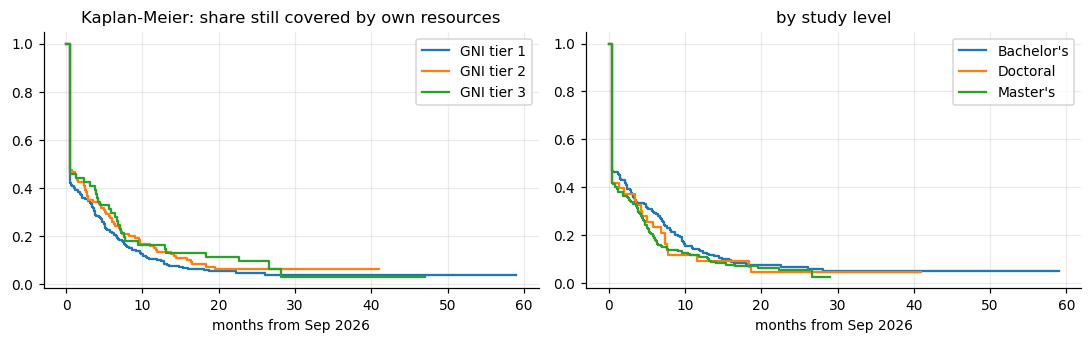

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
kmf = KaplanMeierFitter()
for t, g in E.groupby("gni_tier"):
    kmf.fit(g["T"], g.event, label=f"GNI tier {t}").plot_survival_function(ax=axs[0], ci_show=False)
axs[0].set_title("Kaplan-Meier: share still covered by own resources"); axs[0].set_xlabel("months from Sep 2026")
for s, g in E.groupby("study_level"):
    kmf.fit(g["T"], g.event, label=s).plot_survival_function(ax=axs[1], ci_show=False)
axs[1].set_title("by study level"); axs[1].set_xlabel("months from Sep 2026")
plt.tight_layout(); plt.show()

**What we see (all four of us).** The event is **almost universal**: 389 of the 412 eligible applicants (94%) run out of their own resources before graduating. Only 23 are right-censored, meaning their savings last until completion. 233 eligible applicants (57%) have no savings, so their runway is zero. They all share the same duration (0.5 months), which creates a large block of ties. The Kaplan–Meier curves show the same picture: after one month only 41–47% of applicants are still covered by their own resources, after 12 months 9–16%, and by month 23 (the typical completion time) 5–10%. Tier-1 applicants run out slightly faster than tiers 2 and 3; the differences by study level are small.

The completion dates from the files are consistent with the study levels (Bachelor's and Master's mostly 23 months away, i.e. July 2028; doctoral students more often later).

**Implication.** In this pool, *whether* an applicant runs out is hardly informative. What separates applicants is *how soon*, and for most of them the answer is "immediately". The model has to discriminate within a pool that is almost entirely "in need".

### 3.2 Covariates (feature set) and exclusions

**Used:** log household income of the supporting family, family support and expected personal income as shares of
monthly expenses, housing cost share, annual tuition (in CHF 1,000), dependent children, part-time study, GNI tier
1, first generation, permit F/S/Pending, level (Master's, Doctoral; Bachelor's is the reference).
**Excluded:** savings, the shortfall and other scholarships (they define the duration); gender, age, country,
university, field of study (no criterion; proxy risk); GPA and the resilience flags (not about the financial runway;
used in Step 4).

In [9]:
X = pd.DataFrame(index=E.index)
X["log_household"] = np.log(E.family_household_income_chf.clip(lower=100))
X["family_share"] = E.family_income_chf / E.monthly_expenses_chf
X["personal_income_share"] = E.expected_personal_income_2027_chf / E.monthly_expenses_chf
X["housing_share"] = E.housing_cost_chf / E.monthly_expenses_chf
X["tuition_k"] = E.tuition_fees_per_year_chf / 1000
X["dependent_children"] = E.dependent_children
X["part_time"] = (E.planned_study_mode_2027 == "Part-time").astype(int)
X["tier1"] = (E.gni_tier == 1).astype(int)
X["first_gen"] = E.risk_first_generation
X["permit_F_S_pending"] = E.residency_permit.isin(["F", "S", "Pending"]).astype(int)
X["master"] = (E.study_level == "Master's").astype(int); X["doctoral"] = (E.study_level == "Doctoral").astype(int)
D = X.assign(T=E["T"], event=E.event)
X.describe().T[["mean", "std", "min", "max"]].round(2)

,mean,std,min,max
log_household,7.31,0.81,5.44,9.16
family_share,0.18,0.16,0.02,0.99
personal_income_share,0.23,0.23,0.00,0.89
housing_share,0.49,0.07,0.30,0.67
tuition_k,1.98,1.04,0.30,6.26
dependent_children,0.06,0.28,0.00,2.00
part_time,0.09,0.28,0.00,1.00
tier1,0.56,0.50,0.00,1.00
first_gen,0.58,0.49,0.00,1.00
permit_F_S_pending,0.11,0.32,0.00,1.00


### 3.3 Fit, cross-validated concordance, fold-seed and penalty sensitivity

Validation criterion: **concordance index (C-index)** on held-out folds. This is the probability that, of two
applicants, the model gives the higher hazard to the one who runs out of money first (0.5 = chance, 1 = perfect).
Ties in duration are frequent (all applicants without savings run out "in the first month"). The C-index handles
them by ignoring tied pairs.

In [10]:
cph = CoxPHFitter(penalizer=0.05).fit(D, "T", "event")
display(cph.summary[["coef", "exp(coef)", "se(coef)", "p"]].round(3))
rows = []
for pen in [0.01, 0.05, 0.2]:
    for fs in [1, 7, 2026]:
        np.random.seed(fs)
        sc = k_fold_cross_validation(CoxPHFitter(penalizer=pen), D.sample(frac=1, random_state=fs), "T", "event",
                                     k=5, scoring_method="concordance_index")
        rows.append({"penalizer": pen, "fold seed": fs, "CV C-index mean": np.mean(sc), "min fold": np.min(sc), "max fold": np.max(sc)})
cv = pd.DataFrame(rows)
display(cv.round(3))
print("in-sample C-index (penalizer 0.05):", round(cph.concordance_index_, 3))

,coef,exp(coef),se(coef),p
covariate,,,,
log_household,0.062,1.063,0.097,0.526
family_share,-1.958,0.141,0.482,0.000
personal_income_share,-0.899,0.407,0.263,0.001
housing_share,1.306,3.692,0.779,0.094
tuition_k,0.067,1.069,0.059,0.255
dependent_children,-0.347,0.707,0.195,0.075
part_time,-0.448,0.639,0.224,0.046
tier1,-0.053,0.948,0.131,0.687
first_gen,0.191,1.211,0.101,0.059


,penalizer,fold seed,CV C-index mean,min fold,max fold
0,0.01,1,0.583,0.539,0.660
1,0.01,7,0.576,0.536,0.597
2,0.01,2026,0.582,0.507,0.631
3,0.05,1,0.584,0.537,0.663
4,0.05,7,0.574,0.535,0.594
5,0.05,2026,0.582,0.509,0.632
6,0.20,1,0.580,0.532,0.665
7,0.20,7,0.573,0.540,0.589
8,0.20,2026,0.581,0.510,0.629


in-sample C-index (penalizer 0.05): 0.595


In [11]:
# Ranking stability across penalties, and the proportional-hazards assumption
E["hazard"] = cph.predict_partial_hazard(X)
rk = {pen: CoxPHFitter(penalizer=pen).fit(D, "T", "event").predict_partial_hazard(X) for pen in [0.01, 0.2]}
print("Spearman of hazard ranking, penalizer 0.05 vs 0.01:", round(spearmanr(E.hazard, rk[0.01])[0], 3),
      "| vs 0.2:", round(spearmanr(E.hazard, rk[0.2])[0], 3))
ph = proportional_hazard_test(cph, D, time_transform="rank")
display(ph.summary[["test_statistic", "p"]].round(3).sort_values("p").head(6))

Spearman of hazard ranking, penalizer 0.05 vs 0.01: 0.999 | vs 0.2: 0.994


,test_statistic,p
family_share,16.613,0.000
personal_income_share,20.537,0.000
permit_F_S_pending,1.413,0.235
tier1,1.359,0.244
housing_share,1.043,0.307
part_time,0.946,0.331


**What we see (B and C).**

* **Discrimination is weak:** the cross-validated C-index is about **0.58** (folds 0.51–0.66), barely above chance. It hardly depends on the penalty (0.01–0.2) or the fold seed. The ranking is equally stable across penalties (Spearman ≥ 0.99), so it is *stable*, just not very *informative*.
* **Coefficients:** family support (hazard ratio 0.14 per 100% of expenses) and expected personal income (0.41) protect strongly. A high housing share raises the hazard. Part-time study (0.64) and dependent children (0.71) *lower* the hazard, which is counter-intuitive. GNI tier, permit status and level have no clear effect once the budget structure is known.
* **Proportional hazards are violated** for family share and personal-income share (p < 0.001): their effect changes over time. For a one-off ranking this matters less than for a prediction, but the hazard ratios should not be read as constant effects.

❓ **Question for students:** a C-index of 0.58 means the model orders a random pair correctly about 58% of the time. Is that good enough to drive a funding decision? What would you compare it with?

### 3.4 Human review: does the urgency score match the files?

We read the applicants with the highest predicted hazard who are *censored* (their savings do last until
graduation), and the lowest-hazard applicants who *do* run out. These are the cases where the model's urgency and
the observed runway disagree most.

In [12]:
def excerpt(sid, n=600):
    t = docs[sid]; i = t.find("## Section 4")
    return re.sub(r"\s+", " ", t[i:].split("\n", 3)[-1])[:n]
cols = ["hazard", "event", "T", "runway", "time_to_completion", "savings_chf", "net_gap", "family_household_income_chf", "gni_tier", "study_level"]
hi_cens = E[E.event == 0].nlargest(2, "hazard"); lo_event = E[E.event == 1].nsmallest(2, "hazard")
display(pd.concat([hi_cens, lo_event])[cols].round(2))
for sid in list(hi_cens.index) + list(lo_event.index):
    print(sid, "|", excerpt(sid), "...\n")
print("Spearman, hazard vs shortfall ratio (eligible):", round(spearmanr(E.hazard, E.shortfall_ratio)[0], 2))

,hazard,event,T,runway,time_to_completion,savings_chf,net_gap,family_household_income_chf,gni_tier,study_level
STU000184,1.06,0,23.0,24.25,23.0,11928,491.92,720,1,Bachelor's
STU000007,0.94,0,23.0,49.97,23.0,10240,204.92,1120,1,Bachelor's
STU000280,0.27,1,0.5,0.00,23.0,0,318.00,3970,3,Master's
STU000314,0.31,1,0.5,0.00,29.0,0,604.00,330,1,Master's


STU000184 |  I want to write all numbers honestly, also the ones that are not in my favour. My costs are CHF 2,108 per month. I earn CHF 837 per month working as a cleaner in a hospital, evenings. My brother, who is a shopkeeper in Mashhad and whose household has about CHF 720, sends me CHF 200. I receive a scholarship of CHF 6,949 per year from a foundation for Afghan students, which is paid until December. And I have CHF 11,928 savings, from my work in Iran and eight years of evening work in Switzerland. So yes, on paper my situation is better than for many others. But the scholarship ends in December,  ...

STU000007 |  I am a second-year nursing student at HES-SO La Source, and I have organised my life around a single goal: to become a registered nurse in Switzerland and, one day, to strengthen nursing education in Palestine. My financial situation is carefully managed, but it is fragile, and the most demanding part of my programme is still ahead of me. My monthly costs are CHF 2,0

**Human review of the disagreements.** The predicted hazard correlates strongly with the shortfall ratio (Spearman 0.85). The model mostly rediscovers need from the budget shares. The four disagreement cases are instructive:

* **STU000184** (high hazard, *censored*): the data say the savings (CHF 11,928) last 24.3 months, just beyond completion at 23. The file adds that the external scholarship of CHF 6,949/year **ends in December**. From then on the gap is much larger and the runway much shorter. Here the model's high hazard is *more* accurate than our duration, which assumes the scholarship continues.
* **STU000007** (high hazard, censored): savings last about 50 months, but the file explains that clinical placements become full-time from the next semester, and the care home cannot schedule around them: the income of CHF 1,164 will fall. Again the high hazard is plausible.
* **STU000280** (low hazard, *event*): no savings, so the duration is 0.5. But the gap is only CHF 318 and a spouse earns about CHF 3,970. The low hazard is sensible, and the "event" mostly reflects the zero-savings convention.
* **STU000314** (low hazard, event): part-time law student and interpreter, gap CHF 604, **two children**, supporting household of about CHF 330. The low hazard comes largely from the *negative* coefficient on dependent children. The call's checklist lists *student parent/dependents* as a risk circumstance, yet our model treats children as protective. In the data, applicants with children study part-time more often (17% vs 8%), earn more and hold more savings, so their observed runway is longer on average (7.0 vs 4.6 months). The model has learnt this association.

We consider the last point a modelling choice we cannot defend: the model must not lower the urgency of applicants *because* they have children.

In [13]:
# Revision after the review: refit without `dependent_children`
X2 = X.drop(columns="dependent_children"); D2 = X2.assign(T=E["T"], event=E.event)
cph2 = CoxPHFitter(penalizer=0.05).fit(D2, "T", "event")
np.random.seed(SEED)
sc2 = k_fold_cross_validation(CoxPHFitter(penalizer=0.05), D2.sample(frac=1, random_state=SEED), "T", "event", k=5, scoring_method="concordance_index")
print(f"CV C-index without dependent_children: {np.mean(sc2):.3f} (with: {cv.query('penalizer == 0.05 and `fold seed` == 2026')['CV C-index mean'].iloc[0]:.3f})")
E["hazard_v1"] = E.hazard
E["hazard"] = cph2.predict_partial_hazard(X2)
print("Spearman, hazard v1 vs revised:", round(spearmanr(E.hazard_v1, E.hazard)[0], 3))
pr = lambda c: E[c].rank(pct=True)
for sid in ["STU000314"]:
    print(f"{sid}: hazard percentile {pr('hazard_v1')[sid]:.2f} -> {pr('hazard')[sid]:.2f}")
print("applicants with children, mean hazard percentile:", round(pr("hazard_v1")[E.dependent_children > 0].mean(), 2), "->",
      round(pr("hazard")[E.dependent_children > 0].mean(), 2), f"(n = {(E.dependent_children > 0).sum()})")

CV C-index without dependent_children: 0.570 (with: 0.582)
Spearman, hazard v1 vs revised: 0.976
STU000314: hazard percentile 0.01 -> 0.13
applicants with children, mean hazard percentile: 0.19 -> 0.42 (n = 18)


**Group decision (unanimous): drop `dependent_children` from the hazard model.** The cross-validated C-index falls slightly (0.582 → 0.570). We accept this small loss of fit to remove an association that contradicts the call. The ranking barely changes overall (Spearman 0.98 with the first model). For the 18 eligible applicants with children, the mean hazard percentile rises from 0.19 to 0.42; for STU000314, from 0.01 to 0.13. The revised hazard is used from here on, and the first one is kept in the output (`hazard_v1`).

❓ **Question for students:** we removed a covariate because we disliked the direction of its effect, not because it was statistically wrong. When is it legitimate to remove a predictive variable for normative reasons? Is it different from the protocol's instruction to exclude variables that act as unintended proxies?

---
## Step 4 — Documentation, and from model output to a funding list

*Budget: ~40.6h.*

### 4.1 Draft 1: fund by urgency (predicted hazard) alone

In [14]:
df["hazard"] = E.hazard.reindex(df.index); df["hazard_v1"] = E.hazard_v1.reindex(df.index)

In [15]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# DRAFT 1: predicted hazard (urgency) only; 75% of request; minimum CHF 1,000
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.75, 1000
order = df[df.eligible & (df.request > 0)].sort_values("hazard", ascending=False).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 113 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 4,425


In [16]:
df["award_draft1"] = df.award
f = df.award > 0
print("draft 1 | funded who run out before completion (event = 1):", int(df.loc[f, "event"].sum()), "of", f.sum())
print("draft 1 | eligible with event = 1 and NOT funded:", int((df.eligible & ~f & (df.event == 1) & (df.request > 0)).sum()))
print("draft 1 | median shortfall ratio funded %.2f vs eligible not funded %.2f" % (df.loc[f, "shortfall_ratio"].median(),
      df.loc[df.eligible & ~f, "shortfall_ratio"].median()))

draft 1 | funded who run out before completion (event = 1): 113 of 113
draft 1 | eligible with event = 1 and NOT funded: 273
draft 1 | median shortfall ratio funded 0.88 vs eligible not funded 0.50


**Draft 1 (revised hazard only): 113 awards, CHF 500,000** (mean CHF 4,425, i.e. 75% of each request). All 113 recipients run out before completion, but so do 273 eligible applicants who are not funded. The median shortfall ratio is 0.88 among recipients against 0.50 among eligible applicants not funded. Urgency alone already favours high need. It ignores the call's academic, resilience and diversity criteria (S2–S5), which carry 60% of the call's weights.

### 4.2 Final priority: urgency first, then the call's other criteria

$$\text{priority} = 0.60\cdot\text{pct}(\text{hazard}) + 0.15\cdot(1-\text{pct}(T)) + 0.25\cdot\text{pct}(\text{other})$$

* $T$: the observed duration, i.e. months until the applicant's own resources run out, or the time to completion if
  they never do (censored). A shorter runway means more urgency. This uses the *observed* runway directly, beside the
  model's prediction;
* $\text{other} = 0.25\,\text{pct(progress)} + 0.25\,\text{pct(gpa)} + 0.30\,\text{resil\_count}/5 + 0.20\,[\text{tier}=1 \lor \text{first-gen}]$,
  i.e. the call's criteria S2–S5 that the hazard model does not contain.

Percentiles among eligible applicants. Same award rule (75% of request, minimum CHF 1,000).

In [17]:
pctE = lambda s: s.where(df.eligible).rank(pct=True)
df["other"] = (0.25 * pctE(df.progress) + 0.25 * pctE(df.gpa) + 0.30 * df.resil_count / 5
               + 0.20 * ((df.gni_tier == 1) | (df.risk_first_generation == 1)))
df["priority"] = 0.60 * pctE(df.hazard) + 0.15 * (1 - pctE(df["T"])) + 0.25 * pctE(df.other)

In [18]:
# Translate the model's ranking into a funding list (a HUMAN decision, see Step 4)
# FINAL: 0.60 hazard + 0.15 observed runway + 0.25 other criteria; 75% of request; minimum CHF 1,000
BUDGET, FRACTION, MIN_AWARD = 500_000, 0.75, 1000
order = df[df.eligible & (df.request > 0)].sort_values("priority", ascending=False).index
award, left = pd.Series(0.0, index=df.index), BUDGET
for sid in order:
    amt = float(np.floor(df.at[sid, "request"] * FRACTION))
    if amt < MIN_AWARD:
        continue
    give = min(amt, left)
    if give < MIN_AWARD:
        break
    award[sid] = give
    left -= give
df["award"] = award
df["funding_rank"] = pd.Series(range(1, len(order) + 1), index=order).reindex(df.index)
print(f"funded: {(df.award > 0).sum()} applicants | awarded CHF {df.award.sum():,.0f} | left CHF {BUDGET - df.award.sum():,.0f} "
      f"| mean award CHF {df.loc[df.award > 0, 'award'].mean():,.0f}")

funded: 115 applicants | awarded CHF 500,000 | left CHF 0 | mean award CHF 4,348


In [19]:
f = df.award > 0
print(f"draft 1 -> final: {((df.award > 0) & (df.award_draft1 == 0)).sum()} enter, {((df.award == 0) & (df.award_draft1 > 0)).sum()} leave")
print("final | funded with event = 1:", int(df.loc[f, "event"].sum()), "of", f.sum(), "| censored applicants funded:", int((f & (df.event == 0)).sum()))
print("final | funded by GNI tier:", df.loc[f, "gni_tier"].value_counts().sort_index().to_dict(),
      "| conditional:", int((f & df.conditional).sum()), "| GPA < 2.5:", int((f & (df.gpa < 2.5)).sum()))

draft 1 -> final: 27 enter, 25 leave
final | funded with event = 1: 115 of 115 | censored applicants funded: 0
final | funded by GNI tier: {1: 83, 2: 24, 3: 8} | conditional: 24 | GPA < 2.5: 13


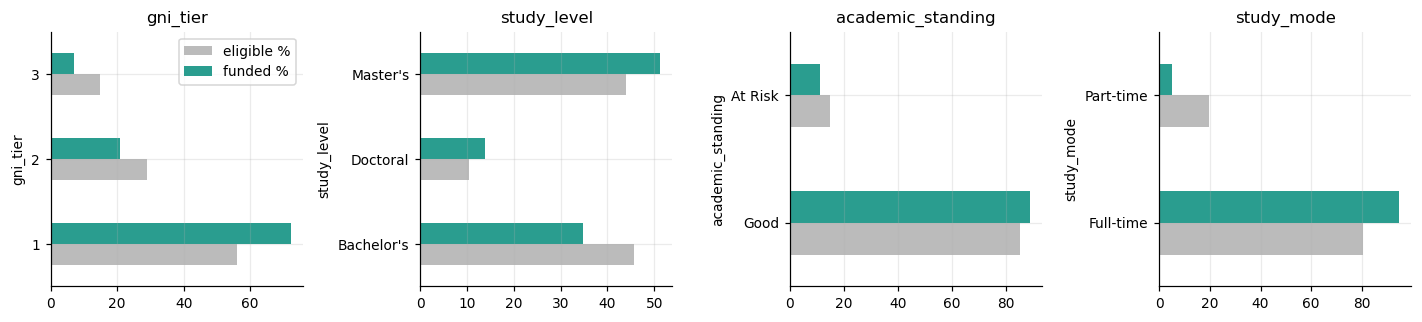

median shortfall ratio  funded: 0.84 | eligible not funded: 0.50


In [20]:
# Who is funded? Composition of the final list against the eligible pool
def share(col):
    e = df.loc[df.eligible, col].astype(str).value_counts(normalize=True).mul(100)
    f = df.loc[df.award > 0, col].astype(str).value_counts(normalize=True).mul(100)
    return pd.DataFrame({"eligible %": e, "funded %": f}).fillna(0).round(1)
fig, axs = plt.subplots(1, 4, figsize=(13, 3))
for ax, col in zip(axs, ["gni_tier", "study_level", "academic_standing", "study_mode"]):
    share(col).plot.barh(ax=ax, color=["#bbbbbb", "#2a9d8f"], legend=(col == "gni_tier"))
    ax.set_title(col)
plt.tight_layout(); plt.show()
print("median shortfall ratio  funded: %.2f | eligible not funded: %.2f" % (
    df.loc[df.award > 0, "shortfall_ratio"].median(), df.loc[df.eligible & (df.award == 0), "shortfall_ratio"].median()))

**Final list: 115 awards, CHF 500,000** (mean CHF 4,348). Compared with draft 1, 27 applicants enter and 25 leave. All recipients run out before completion, and none of the 23 censored applicants is funded. By GNI tier: 83 / 24 / 8. 24 awards are conditional (pending permit or GPA below 2.5, 13 with GPA < 2.5). The median shortfall ratio is 0.84 among recipients against 0.50 among eligible applicants not funded.

Our award rule (75% of each request) yields 115 awards, below the call's 140–180 estimate. We accept this: a survival framing argues for awards large enough to keep students enrolled until graduation. We record it as the main point for discussion with the committee.

In [21]:
# Output files: the full decision path (all 500) and the final allocation (funded only)
df["status"] = np.select([df.award > 0, ~df.eligible], [np.where(df.conditional, "funded (conditional)", "funded"),
                         "not eligible"], "eligible, not funded")
df["reason"] = np.select([df.award > 0, ~df.eligible], ["rank " + df.funding_rank.astype("Int64").astype(str) + np.where(df.event == 1, ": runs out before completion", ": runway reaches completion") + "; 75% of request", "failed: " + df[HARD].apply(lambda r: ", ".join(h for h in HARD if r[h].startswith("fail")), axis=1)], "eligible; budget exhausted before this rank")
INPUTS = ["student_id", "study_level", "study_mode", "residency_permit", "gni_tier", "geographic_region", "gpa",
          "academic_standing", "need_2027", "shortfall_ratio", "family_household_income_chf", "savings_chf",
          "external_scholarship_amount_chf", "risk_count", "resil_count", "completion_year", "completion_month",
          "months_in_grant"]
STEPS = HARD + ["eligible", "conditional"] + ["net_gap", "savings_after_bridge", "runway", "time_to_completion", "T", "event", "hazard_v1", "hazard", "other", "award_draft1", "priority"] + ["request", "funding_rank", "award", "status", "reason"]
decision_progression = df[INPUTS + STEPS]
decision_progression.to_csv("decision_progression.csv", index=False)
final = decision_progression[decision_progression.award > 0].sort_values("funding_rank")
final.to_csv("final_allocation.csv", index=False)
print("decision_progression.csv:", decision_progression.shape, "| final_allocation.csv:", final.shape,
      f"| total CHF {final.award.sum():,.0f}")
final.head(8)

decision_progression.csv: (500, 43) | final_allocation.csv: (115, 43) | total CHF 500,000


,student_id,study_level,study_mode,residency_permit,gni_tier,geographic_region,gpa,academic_standing,need_2027,shortfall_ratio,family_household_income_chf,savings_chf,external_scholarship_amount_chf,risk_count,resil_count,...,savings_after_bridge,runway,time_to_completion,T,event,hazard_v1,hazard,other,award_draft1,priority,request,funding_rank,award,status,reason
STU000381,STU000381,Master's,Full-time,B,1,Sub-Saharan Africa,4.00,Good,1924,0.805358,960,0,7463,1,5,...,0.0,0.000000,23.0,0.500000,1,1.726412,1.662526,0.929915,4468.0,0.939017,5958.0,1.0,4468.0,funded,rank 1: runs out before completion; 75% of req...
STU000024,STU000024,Bachelor's,Full-time,B,1,Middle East/North Africa,3.02,Good,2214,0.940527,550,0,0,2,3,...,0.0,0.000000,23.0,0.500000,1,1.639648,1.682443,0.746505,5499.0,0.917658,7333.0,2.0,5499.0,funded,rank 2: runs out before completion; 75% of req...
STU000274,STU000274,Bachelor's,Full-time,Pending,1,Sub-Saharan Africa,3.13,Good,1960,0.937799,540,2375,5151,4,3,...,0.0,1.551527,23.0,1.551527,1,1.794191,1.799348,0.777148,5499.0,0.891626,7333.0,3.0,5499.0,funded (conditional),rank 3: runs out before completion; 75% of req...
STU000016,STU000016,Master's,Full-time,B,1,South Asia,3.64,Good,1992,0.841216,1260,0,0,3,3,...,0.0,0.000000,23.0,0.500000,1,1.655643,1.635745,0.701905,4468.0,0.889138,5958.0,4.0,4468.0,funded,rank 4: runs out before completion; 75% of req...
STU000335,STU000335,Doctoral,Full-time,Pending,1,South Asia,3.63,Good,2263,0.930127,840,7717,0,5,3,...,0.0,3.410075,23.0,3.410075,1,1.832684,1.785861,0.824175,3437.0,0.888956,4583.0,5.0,3437.0,funded (conditional),rank 5: runs out before completion; 75% of req...
STU000460,STU000460,Doctoral,Full-time,F,1,South Asia,3.30,Good,1869,0.820097,1820,0,0,2,3,...,0.0,0.000000,29.0,0.500000,1,1.628479,1.578932,0.746505,3750.0,0.888532,5000.0,6.0,3750.0,funded,rank 6: runs out before completion; 75% of req...
STU000072,STU000072,Master's,Full-time,Pending,1,South Asia,3.37,Good,1567,0.902130,800,0,7872,3,3,...,0.0,0.000000,23.0,0.500000,1,1.665154,1.603984,0.716165,4468.0,0.885619,5958.0,7.0,4468.0,funded (conditional),rank 7: runs out before completion; 75% of req...
STU000249,STU000249,Master's,Full-time,B,1,Sub-Saharan Africa,3.59,Good,2295,0.891262,1130,4284,0,1,5,...,0.0,1.866667,23.0,1.866667,1,1.657588,1.647783,0.814017,4468.0,0.881553,5958.0,8.0,4468.0,funded,rank 8: runs out before completion; 75% of req...


### 4.3 Which decisions are the model's, and which are ours

| Decision | Made by | How |
|---|---|---|
| Definition of runway, time to completion, event and censoring | Humans (us) | Step 2, 3.1 |
| Covariates, and excluding savings/gap to avoid circularity | Humans (us) | Step 3.2 |
| Urgency (partial hazard) for every applicant | Model | Cox proportional hazards, penalizer 0.05 |
| Dropping `dependent_children` from the model | Humans (us) | after the review (3.4) |
| Savings rule (only savings left after Sep 2026 – Aug 2027 count) | Humans (us) | Step 1.3 |
| Weight of predicted urgency vs observed runway vs other criteria (0.60/0.15/0.25) | Humans (us) | revised after draft 1 (4.2) |
| Award size (75% of request, minimum CHF 1,000) | Humans (us) | Step 1.3 |


### 4.4 Reproducibility

Deterministic given the input files (the Cox fit has no random element; CV folds are seeded). Specification: runway,
time to completion, event and censoring (Step 2, 3.1), covariates (3.2, without `dependent_children` after 3.4), `CoxPHFitter(penalizer=0.05)`, final priority
and award rule (4.2).

### 4.5 Summary of our decision path

1. 500 → **412 eligible** (76 no shortfall in the grant period; 23 Permit C with household ≥ CHF 5,500). 74 of the eligible are conditional.
2. Runway = savings ÷ net monthly gap. Event = runs out before completion (389 of 412). 23 right-censored.
3. Cox PH on the budget structure (without savings/gap): **CV C-index ≈ 0.58**; PH violated for two covariates. The hazard mainly reproduces the shortfall ratio (ρ = 0.85).
4. Review: two censored cases are truly urgent (a scholarship ending, an income ending), which the data miss. `dependent_children` was removed because the model treated children as protective.
5. Draft 1 (hazard only, 113 awards) → **final: 0.60 hazard + 0.15 observed runway + 0.25 other criteria, 75% of request → 115 awards, CHF 500,000**.

Output files: `decision_progression.csv` (all 500: runway, duration, event, both hazards, draft-1 and final awards) and `final_allocation.csv`.